# EDA Precinct6 chica — `witfoo/precinct6-cybersecurity` (2M)

Objetivo: describir **todas las variables interesantes** para decidir modelo después.
Guía proyecto: fenómeno SOC, 3 prepros, 3 modelos + complejidad, deploy.

**Fuentes:**
- Dataset 2M: https://huggingface.co/datasets/witfoo/precinct6-cybersecurity
- Dataset 114M: https://huggingface.co/datasets/witfoo/precinct6-cybersecurity-100m
- Código generación: https://github.com/witfoo/dataset-from-precinct6
- Research: https://witfoo.com/research
- ATT&CK: https://attack.mitre.org/ | NodLink: https://arxiv.org/abs/2311.02331 | CybORG: https://arxiv.org/abs/2002.10667
- EDA SOC: imbalance manda (DeepCASE https://arxiv.org/html/2507.01571), usar PR-AUC no accuracy, stratified k-fold, cost-sensitive/focal loss, tuning reglas.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

plt.rcParams['figure.figsize'] = (10, 4)
SIG = Path('data/signals/signals.parquet')
INC = Path('data/signals/incident_signals.parquet')
NODES = Path('data/graph/nodes.parquet')
EDGES = Path('data/graph/edges-00000.parquet')
REPORTS = Path('data/graph/attack_reports.parquet')
print('archivos:', [p.exists() for p in [SIG, INC, NODES, EDGES, REPORTS]])

archivos: [True, True, True, True, True]


## 1. Overview signals (2,011,674 x 38)
38 columnas: timestamp, event_time, timestamp_source, origin, org_id, artifact_id, message_type, stream_name, pipeline, src/dst_ip, src/dst_port, protocol, src/dst_host, username, action, severity, vendor_code, message_sanitized, label_binary, label_confidence, attack_techniques/tactics, defense_techniques, mo_name, suspicion_score, lifecycle_stage, disposition, disposition_category, is_false_positive, status_name, incident_ids, matched_rules, set_roles, product_name, vendor_name.

In [2]:
df = pd.read_parquet(SIG)
print(df.shape)
print(df.dtypes)
print('\nmiss %:')
print((df.isna().sum() / len(df) * 100).sort_values(ascending=False).head(12))
print('\nvacíos string %:')
print(((df == '').sum() / len(df) * 100).sort_values(ascending=False).head(12))
print('\nduplicados artifact_id:', df.artifact_id.duplicated().sum())
print('memoria MB:', df.memory_usage(deep=True).sum() / 1e6)

(2011674, 38)
timestamp               float64
event_time              float64
timestamp_source         object
origin                   object
org_id                   object
artifact_id              object
message_type             object
stream_name              object
pipeline                 object
src_ip                   object
dst_ip                   object
src_port                 object
dst_port                 object
protocol                 object
src_host                 object
dst_host                 object
username                 object
action                   object
severity                 object
vendor_code              object
message_sanitized        object
label_binary             object
label_confidence        float64
attack_techniques        object
attack_tactics           object
defense_techniques       object
mo_name                  object
suspicion_score         float64
lifecycle_stage          object
disposition              object
disposition_category     o

event_time          75.450794
timestamp            0.000000
timestamp_source     0.000000
origin               0.000000
org_id               0.000000
artifact_id          0.000000
message_type         0.000000
stream_name          0.000000
pipeline             0.000000
src_ip               0.000000
dst_ip               0.000000
src_port             0.000000
dtype: float64

vacíos string %:


mo_name        99.615842
status_name    99.615842
protocol       94.275315
dst_port       93.626452
dst_ip         93.161019
src_port       89.680634
dst_host       82.539020
action         72.805981
username       64.126096
src_ip         60.315190
severity       49.275032
vendor_code    44.244395
dtype: float64

duplicados artifact_id: 0


memoria MB: 6291.012229


## 2. Target: label_binary (desbalance extremo)
Esperado README: benign 94.31% / suspicious 5.31% / malicious 0.38%. IR ~245:1. Esto define todo el modelado.

label_binary
benign        1897153
suspicious     106793
malicious        7728
Name: count, dtype: int64
label_binary
benign        94.307179
suspicious     5.308663
malicious      0.384158
Name: proportion, dtype: float64


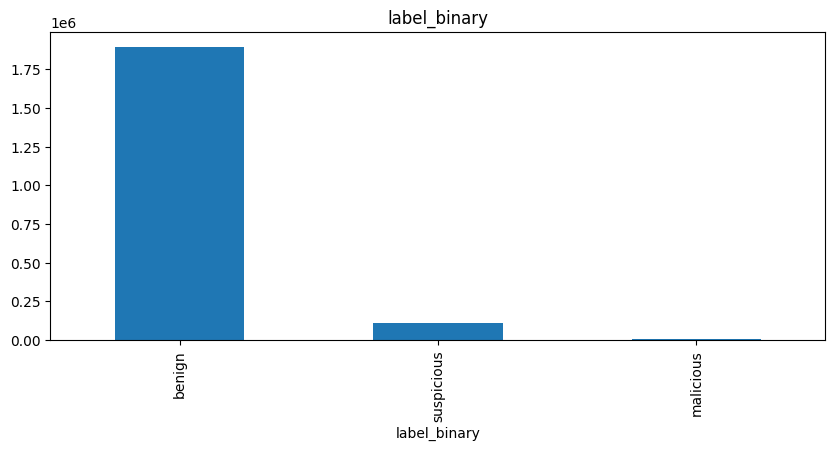


label_confidence por label:
                  count      mean       std  min  25%     50%       75%   max
label_binary                                                                 
benign        1897153.0  0.500000  0.000000  0.5  0.5  0.5000  0.500000  0.50
malicious        7728.0  0.787450  0.138010  0.6  0.6  0.8875  0.894531  0.95
suspicious     106793.0  0.600115  0.003392  0.6  0.6  0.6000  0.600000  0.70


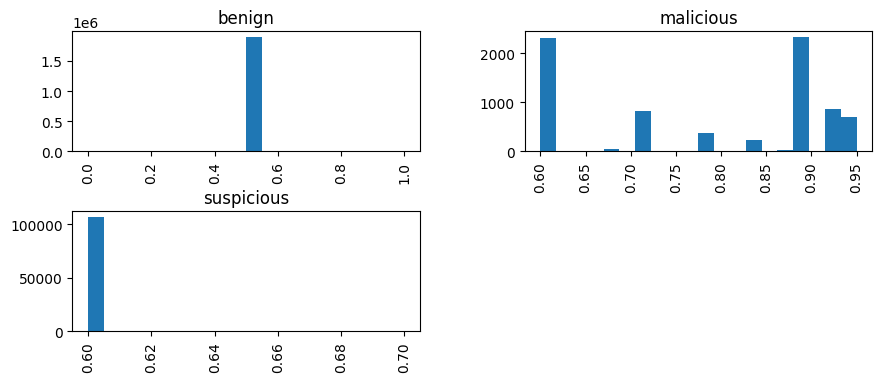


suspicion_score por label:
                  count     mean       std   min       25%     50%       75%  \
label_binary                                                                   
benign        1897153.0  0.00000  0.000000  0.00  0.000000  0.0000  0.000000   
malicious        7728.0  0.69499  0.278612  0.25  0.409375  0.8875  0.894531   
suspicious     106793.0  0.00000  0.000000  0.00  0.000000  0.0000  0.000000   

                  max  
label_binary           
benign        0.00000  
malicious     0.96625  
suspicious    0.00000  


In [3]:
print(df.label_binary.value_counts())
print(df.label_binary.value_counts(normalize=True) * 100)
df.label_binary.value_counts().plot(kind='bar'); plt.title('label_binary'); plt.show()
print('\nlabel_confidence por label:')
print(df.groupby('label_binary').label_confidence.describe())
df.hist(column='label_confidence', by='label_binary', bins=20); plt.show()
print('\nsuspicion_score por label:')
print(df.groupby('label_binary').suspicion_score.describe())

## 3. Temporal: timestamp vs event_time
Live 2024-07-26 → 2024-08-01. timestamp=ingesta Precinct, event_time=device clock (muchos NaN). Revisar lag y cobertura por día/hora y por label.

2024-07-26 11:10:23.729254961+00:00 2024-08-01 06:00:03.239708900+00:00
event_time NaN %: 75.45079371707344
count    493850.000000
mean          1.382109
std          62.047688
min           0.000361
25%           0.002075
50%           0.002712
75%           0.003239
max        2919.430528
Name: lag_h, dtype: float64


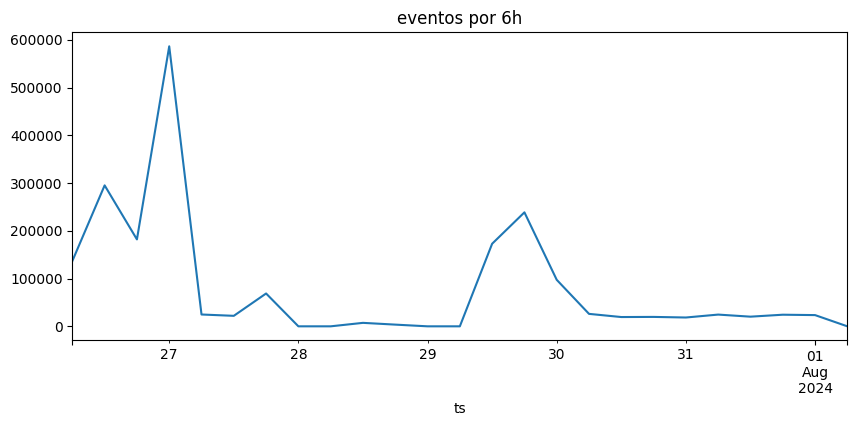

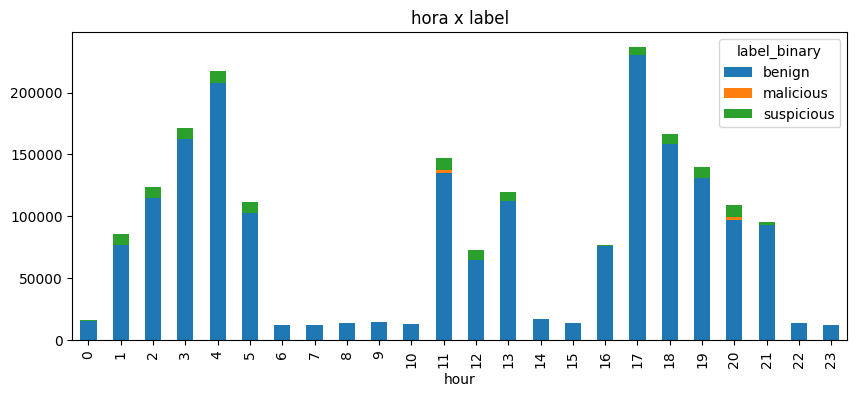

label_binary  benign  malicious  suspicious
ts                                         
2024-07-26    560534       3260       50119
2024-07-27    655920        916       44912
2024-07-28     10822          0           0
2024-07-29    397315       3515       10734
2024-07-30    161715         37         816
2024-07-31     87364          0         188
2024-08-01     23483          0          24


In [4]:
df['ts'] = pd.to_datetime(df.timestamp, unit='s', utc=True)
print(df.ts.min(), df.ts.max())
print('event_time NaN %:', df.event_time.isna().mean() * 100)
df['lag_h'] = (df.timestamp - df.event_time) / 3600
print(df.lag_h.describe())
df.set_index('ts').resample('6h').size().plot(); plt.title('eventos por 6h'); plt.show()
df['hour'] = df.ts.dt.hour
pd.crosstab(df.hour, df.label_binary).plot(kind='bar', stacked=True); plt.title('hora x label'); plt.show()
print(df.groupby([df.ts.dt.date, 'label_binary']).size().unstack(fill_value=0))

## 4. Orgs (cobertura desigual)
README: ORG-0004 996k, ORG-0005 577k, ORG-0003 434k, ORG-0001 5k. Malicious solo en 0004/0005/0003.

In [5]:
print(pd.crosstab(df.org_id, df.label_binary))
print(pd.crosstab(df.org_id, df.label_binary, normalize='index') * 100)
print('\ntimestamp_source:', df.timestamp_source.value_counts())

label_binary  benign  malicious  suspicious
org_id                                     
ORG-0001        4958          0          10
ORG-0003      433775         16         113
ORG-0004      976694       4176       15115
ORG-0005      481726       3536       91555


label_binary     benign  malicious  suspicious
org_id                                        
ORG-0001      99.798712   0.000000    0.201288
ORG-0003      99.970270   0.003687    0.026043
ORG-0004      98.063123   0.419283    1.517593
ORG-0005      83.514529   0.613019   15.872452

timestamp_source: timestamp_source
artifact.timeuuid    2011674
Name: count, dtype: int64


## 5. Productos / streams / pipelines
Top streams: aws_cloudtrail_events, microsoft-windows-security-auditing, windows_security_audit, vcenter, cisco_asa... Ver cuáles concentran malicious.

In [6]:
for c in ['stream_name', 'product_name', 'vendor_name', 'pipeline', 'message_type']:
    print(f'\n=== {c} top10 ==='); print(df[c].value_counts().head(10))
print('\n--- message_type x label (top malicious) ---')
print(pd.crosstab(df.message_type, df.label_binary)['malicious'].sort_values(ascending=False).head(15))
print('\n--- stream x label malicious share ---')
ct = pd.crosstab(df.stream_name, df.label_binary, normalize='index') * 100
print(ct.sort_values('malicious', ascending=False).head(10))


=== stream_name top10 ===
stream_name
aws_cloudtrail_events                  543159
microsoft-windows-security-auditing    421587
windows_security_audit                 336425
vcenter                                266201
java_stack_trace                       154465
cisco_asa                               95143
no_useful_info                          48246
aws_cloud_trail                         34484
dnsmasq                                 34110
aws_vpc_flow_log                        19219
Name: count, dtype: int64

=== product_name top10 ===
product_name
AWS Instance Backup         543159
Windows Active Directory    421587
Windows Logs                336425
                            303229
VMWare VCenter              266201
ASA Firewall                 95143
AWS VPC Security             19219
Barracuda WAF                14870
Linux PAM                     8685
ManageEngine ADManager        1275
Name: count, dtype: int64

=== vendor_name top10 ===
vendor_name
Microsoft          

pipeline
syslog            1467634
aws_cloudtrail     543159
network_flows         881
Name: count, dtype: int64

=== message_type top10 ===


message_type
security_audit_event    336425
management_message      266320
java_error              154491
4662                    115553
5156                    101277
firewall_action          95062
4658                     78706
GetLogEvents             61210
AssumeRole               57676
unknown                  52039
Name: count, dtype: int64

--- message_type x label (top malicious) ---


message_type
network_flow_data            4156
firewall_action              3525
endpoint_protection_event      20
auth_failure                   16
GEO_IP_BLOCK                    4
GRIP_IP_BLACKLISTED             2
MALFORMED_VERSION               2
SLASH_DOT_IN_URL                2
UNKNOWN_CONTENT_TYPE            1
102                             0
1023                            0
1032                            0
1035                            0
104                             0
1043                            0
Name: malicious, dtype: int64

--- stream x label malicious share ---


label_binary                             benign  malicious  suspicious
stream_name                                                           
Crowdstrike Detection                  0.000000  34.482759   65.517241
aws_vpc_flow_log                       0.000000  21.624434   78.375566
cisco_asa                              0.085135   3.704949   96.209916
barracuda_waf                         99.804976   0.073974    0.121049
microsoft-windows-security-auditing   99.969401   0.003795    0.026803
Crowdstrike Asset Inventory          100.000000   0.000000    0.000000
USER-0700                            100.000000   0.000000    0.000000
.net runtime                         100.000000   0.000000    0.000000
Integrations Status                  100.000000   0.000000    0.000000
DUO Asset Inventory                  100.000000   0.000000    0.000000


## 6. Red: protocolo, puertos, hosts, IPs
protocol 6=TCP 17=UDP 1=ICMP. IPs sanitizadas (HMAC). Cardinalidad hosts = feature grafo.

In [7]:
print('protocol:', df.protocol.value_counts().head())
print('\ndst_port top:', df.dst_port.value_counts().head(10))
print('\nsrc_port top:', df.src_port.value_counts().head(10))
for c in ['src_host', 'dst_host', 'src_ip', 'dst_ip', 'username']:
    print(c, 'nunique:', df[c].nunique(), '| vacíos %:', (df[c] == '').mean() * 100)
print('\nTop src_host:', df.src_host.value_counts().head(5).to_dict())
print('Top dst_port en malicious:', df[df.label_binary == 'malicious'].dst_port.value_counts().head(10).to_dict())

protocol: protocol
      1896512
17      88007
6       24491
1        2655
88          8
Name: count, dtype: int64

dst_port top: dst_port
         1883459
53         81699
443        15147
123         4759
135         3808
45367       1987
0            862
80           646
6514         551
23           328
Name: count, dtype: int64



src_port top: src_port
         1804082
45367       3234
0           2158
54706       1636
54428        675
58914        228
54934        214
41740        203
63479        203
54891        201
Name: count, dtype: int64


src_host nunique: 748 | vacíos %: 0.0


dst_host nunique: 20 | vacíos %: 82.5390197417673


src_ip nunique: 3917 | vacíos %: 60.315190234600635


dst_ip nunique: 530 | vacíos %: 93.16101913133042


username nunique: 10275 | vacíos %: 64.12609597777771

Top src_host: {'HOST-0028': 543159, '10.135.191.70': 458776, 'HOST-0032': 131249, '10.108.101.52': 95143, 'HOST-0061': 90419}


Top dst_port en malicious: {'45367': 585, '135': 450, '53': 379, '80': 126, '0': 102, '23': 85, '': 70, '6514': 55, '443': 49, '1800': 43}


## 7. Acción / severidad / usuario
action: block/permit/logon... severity: warning/info... username USER-NNNN compartido con nodos cred.

In [8]:
print('action:', df.action.value_counts().head(10).to_dict())
print('severity:', df.severity.value_counts().head(10).to_dict())
print(pd.crosstab(df.action, df.label_binary))
print('\nvendor_code top:', df.vendor_code.value_counts().head(10).to_dict())
print('\nusername vacío % por label:')
print(df.assign(nouser=df.username == '').groupby('label_binary').nouser.mean() * 100)

action: {'': 1464619, 'File System': 117934, 'Directory Service Access': 115332, 'block': 114310, 'Filtering Platform Connection': 106589, 'Handle Manipulation': 39066, 'Logon': 14083, 'Logoff': 6979, 'Security Group Management': 6394, 'Credential Validation': 5445}
severity: {'': 991253, 'informational': 479472, 'Info': 427432, 'warning': 95150, 'notice': 17699, 'error': 616, 'alert': 30, 'debug': 16, 'Start': 4, 'critical': 2}


label_binary                      benign  malicious  suspicious
action                                                         
                                 1464537         20          62
Audit Policy Change                   20          0           0
Authorization Policy Change          449          0           0
Backup                               137          0           0
Credential Validation               5445          0           0
Detailed File Share                   24          0           0
Directory Service Access          115332          0           0
Directory Service Changes             60          0           0
DnsRegistration                        2          0           0
File Share                          1221          0           0
File System                       117934          0           0
Filtering Platform Connection     106589          0           0
General                              131          0           0
Group Membership                     130

label_binary
benign        61.968645
malicious     99.391822
suspicious    99.900743
Name: nouser, dtype: float64


## 8. ATT&CK + incidente (JSON arrays como string)
attack_techniques ej '["T1041","T1190"]', mo_name ej Data Theft, lifecycle_stage, set_roles, matched_rules. Vacío en benign.

In [9]:
def top_json(col, n=15):
    c = Counter()
    for v in df.loc[df[col].notna() & (df[col] != ''), col].head(300000):
        try: c.update(json.loads(v))
        except: pass
    return c.most_common(n)

print('mo_name:', df.mo_name.value_counts().head(10).to_dict())
print('lifecycle:', df.lifecycle_stage.value_counts().head(10).to_dict())
print('ATT&CK techniques:', top_json('attack_techniques'))
print('ATT&CK tactics:', top_json('attack_tactics'))
print('defense:', top_json('defense_techniques'))
print('set_roles:', top_json('set_roles'))
print('matched_rules:', top_json('matched_rules'))
print('\nmo_name x label:'); print(pd.crosstab(df.mo_name.fillna('(vacio)'), df.label_binary).sort_values('malicious', ascending=False).head(10))

mo_name: {'': 2003946, 'Data Theft': 7728}
lifecycle: {'none': 1897153, 'initial-compromise': 106779, 'complete-mission': 7742}


ATT&CK techniques: [('T1190', 12385), ('T1041', 3095), ('T1567', 3088), ('T1204', 7)]


ATT&CK tactics: [('TA0001', 12385), ('TA0002', 12335), ('TA0009', 3095), ('TA0010', 3095)]


defense: []


set_roles: [('Exploiting Host', 12385), ('Exploiting Target', 12385), ('Suspicious User', 10), ('Exfiltration Host', 7), ('Exfiltration Target', 7), ('Malicious File', 7)]


matched_rules: [('Blocked Action', 12336), ('Authentication Failure', 70), ('Crowdstrike Detection', 14), ('Symantec DLP Detection', 7)]

mo_name x label:


label_binary   benign  malicious  suspicious
mo_name                                     
Data Theft          0       7728           0
              1897153          0      106793


## 9. Disposition (ground truth = motor Precinct, no analista)
automated: Unprocessed/Disrupted/Open/Cold Case. Analista: Resolved/Dismissed/False Positive (raros).

In [10]:
print(pd.crosstab(df.disposition, df.label_binary))
print('\ndisposition_category:', pd.crosstab(df.disposition_category, df.label_binary))
print('\nis_false_positive:', pd.crosstab(df.is_false_positive, df.label_binary))

label_binary   benign  malicious  suspicious
disposition                                 
Cold Case           0          3           0
Disrupted           0       5779           0
Open                0         15           0
Unprocessed   1897153       1931      106793



disposition_category: label_binary           benign  malicious  suspicious
disposition_category                                
automated             1897153       7728      106793

is_false_positive: label_binary        benign  malicious  suspicious
is_false_positive                                
False              1897153       7728      106793


## 10. Texto libre message_sanitized
Log crudo sanitizado. Longitud y tokens separan bien firewall vs windows. Base para modelo 2 (TF-IDF).

                  count         mean          std    min    25%    50%  \
label_binary                                                             
benign        1897153.0  1012.574299  1411.197900    0.0    0.0  234.0   
malicious        7728.0   154.528209   294.947057  106.0  114.0  115.0   
suspicious     106793.0   156.658723   148.232398  102.0  155.0  157.0   

                 75%      max  
label_binary                   
benign        1813.0  65116.0  
malicious      159.0   6255.0  
suspicious     158.0  11553.0  


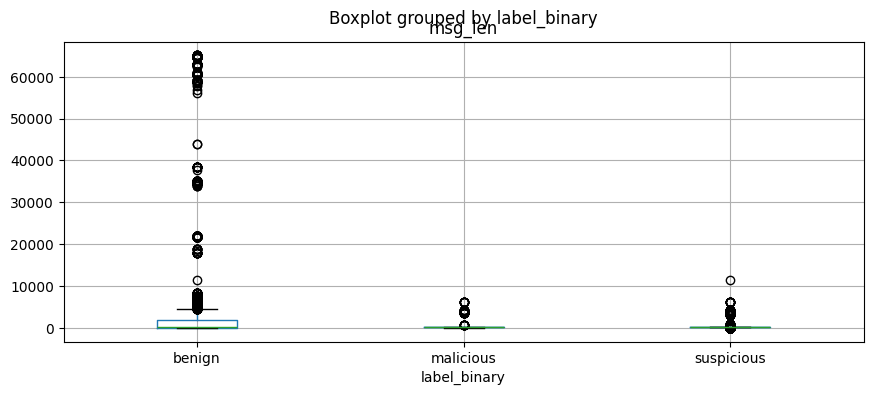

tokens malicious: [('reject', 1995), ('name', 60), ('logon', 55), ('information', 45), ('process', 35), ('host', 30), ('event', 25), ('which', 25), ('nthe', 25), ('type', 20), ('taccount', 20), ('services', 20), ('request', 20), ('fields', 20), ('indicate', 20)]


tokens benign: [('name', 9547), ('host', 8080), ('event', 6371), ('windows', 5310), ('security', 5294), ('version', 5263), ('winlogbeat', 4692), ('provider', 4685), ('example', 4574), ('internal', 4554), ('information', 4329), ('type', 4130), ('microsoft', 3210), ('auditing', 3110), ('success', 3109)]

--- ejemplo malicious ---
WitFoo-WinLogBeat ::: {"@metadata":{"beat":"winlogbeat","type":"_doc","version":"8.2.2"},"@timestamp":"2024-07-27T03:30:43.277Z","agent":{"ephemeral_id":"c7c916ce-56ef-4255-9f46-4ca9ce1b5050","id":"9c19b391-75f6-44e4-a324-d6fa6da22ca7","name":"HOST-0250","type":"winlogbeat","version":"8.2.2"},"ecs":{"version":"8.0.0"},"event":{"action":"Logon","code":"4625","created":"2024-07-27T03:30:44.632Z","kind":"event","outcome":"failure","provider":"Microsoft-Windows-Security-Auditing"},"host":{"name":"host-0014.example.internal"},"log":{"level":"information"},"message":"An account failed to log on.\n\n

--- ejemplo benign ---


Jan 19 23:45:01 HOST-0001 CROND[1933212]: (USER-0001) CMD (if [ -f /epic/redalert/bin/ra_sched ]; then /epic/redalert/bin/ra_sched --monitor_scheduler > /dev/null 2>&1 ; fi)


In [11]:
df['msg_len'] = df.message_sanitized.str.len()
print(df.groupby('label_binary').msg_len.describe())
df.boxplot(column='msg_len', by='label_binary'); plt.show()
from collections import Counter as C
import re
toks = C()
for t in df[df.label_binary == 'malicious'].message_sanitized.head(2000): toks.update(re.findall(r'[A-Za-z]{4,}', t.lower()))
print('tokens malicious:', toks.most_common(15))
toks2 = C()
for t in df[df.label_binary == 'benign'].message_sanitized.head(2000): toks2.update(re.findall(r'[A-Za-z]{4,}', t.lower()))
print('tokens benign:', toks2.most_common(15))
print('\n--- ejemplo malicious ---'); print(df[df.label_binary=='malicious'].message_sanitized.iloc[0][:600])
print('\n--- ejemplo benign ---'); print(df[df.label_binary=='benign'].message_sanitized.iloc[0][:600])

## 11. Las otras 4 tablas
incident_signals 238k (100% malicious histórico 2022-2024), nodes 47k, edges 1.7M, reports 51k.

In [12]:
inc = pd.read_parquet(INC); print('incident_signals:', inc.shape, inc.label_binary.unique())
print('rango:', pd.to_datetime(inc.timestamp, unit='s', utc=True).min(), '→', pd.to_datetime(inc.timestamp, unit='s', utc=True).max())
nodes = pd.read_parquet(NODES); print('\nnodes:', nodes.shape); print(nodes.type.value_counts())
edges = pd.read_parquet(EDGES); print('\nedges:', edges.shape); print(edges.type.value_counts())
rep = pd.read_parquet(REPORTS); print('\nreports:', rep.shape); print(rep.mo_name.value_counts().head(8).to_dict())
rep['len'] = rep.report_text.str.len(); print(rep['len'].describe())
print(rep.report_text.iloc[0][:800])

incident_signals: (238511, 38) ['malicious']
rango: 2022-05-30 14:43:45+00:00 → 2024-07-28 16:39:47+00:00



nodes: (47585, 3)
type
HOST          36974
CREDENTIAL    10575
FILE             29
SERVICE           6
ACTOR             1
Name: count, dtype: int64



edges: (1740438, 7)
type
USER_ACTION      692375
AUDIT_EVENT      336425
INCIDENT_LINK    335645
NETWORK_FLOW     323376
EVENT             45063
DNS_RESOLVE        7554
Name: count, dtype: int64

reports: (51371, 6)
{'Data Theft': 51370, 'Phishing': 1}
count    51371.000000
mean      1150.664130
std         43.153315
min       1049.000000
25%       1125.000000
50%       1136.000000
75%       1143.000000
max       1390.000000
Name: len, dtype: float64
Incident `97d12b00-a932-11ed-a973-7df772fdd65e` (`Bitter Reindeer 230971`) was classified by WitFoo Precinct as **Data Theft** with a suspicion score of 0.25 and a final disposition of **Unprocessed** (`disposition_category=automated`). The attack chain began at `2023-02-10T11:03:46Z` and was last observed at `2023-02-10T11:03:46Z`. The incident graph contains 8 triggering signals, 2 nodes, 1 edge. WitFoo classification roles assigned: Exploiting Host, Exploiting Target. Detection rules triggered: "ASA Deny", "Blocked Action". Security pr

## 12. Conclusiones para modelado

**Tarea recomendada:** clasificación 3 clases (benign/suspicious/malicious) o binaria malicious vs resto sobre `signals`.
- IR 245:1 → métrica PR-AUC/F1-macro, nunca accuracy. Stratified k-fold temporal (train ≤2024-07-29, test después) por drift.
- 3 prepros: (1) tabular (one-hot message_type/stream/protocol + scaling ports/lag), (2) texto TF-IDF 5k sobre message_sanitized, (3) grafo (grado host/user desde nodes/edges).
- 3 modelos: (a) XGBoost tabular, (b) LogReg TF-IDF, (c) MLP fusión o GNN simple. Complejidad: XGBoost O(T·d·n log n), LogReg O(n·vocab), GNN O(E).
- Deploy: API SOC que recibe log → devuelve label + técnicas ATT&CK + reporte.
- Ojo: labels = motor Precinct (imperfecto), disposition automated; filtrar `is_false_positive`; malicious concentrado ORG-0004/0005.